# 10 – ABSA 4 khía cạnh và phân tích kinh doanh (P5 kết quả ABSA, P6 top 3 vấn đề)

**ABSA bằng từ điển + mô hình cảm xúc** (`src/aspects.py`):
1. Chuẩn hóa văn bản (chưa tách từ) và tách thành mệnh đề theo dấu câu và các từ "nhưng", "mà", "tuy".
2. Mệnh đề chứa từ khóa của khía cạnh nào thì thuộc khía cạnh đó.
3. Chạy mô hình cảm xúc (TF-IDF+LR, A+B) trên **mệnh đề**, không chạy trên cả câu.

Vì sao không học ABSA từ ViSD4SA: ViSD4SA không có khía cạnh giao hàng (chỉ 51 review nhắc tới), và chỉ gồm điện thoại. Hướng mở rộng: huấn luyện bộ phân loại riêng cho từng khía cạnh trên các cột `chat_luong`, `gia_ca`, `dich_vu` của ViSD4SA.

In [1]:
import sys, os, joblib
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, precision_recall_fscore_support
from src.data import load_gold, load_category, ASPECTS, P
from src.aspects import absa, detect_aspects, ASPECT_KEYWORDS
from src.preprocess import preprocess

FIG, REP, MOD = "../figures", "../report", "../models"
model = joblib.load(f"{MOD}/tfidf_lr_AB.joblib")
ASP_VI = {"giao_hang": "Giao hàng", "chat_luong": "Chất lượng", "gia_ca": "Giá cả", "dich_vu": "Dịch vụ"}

t = "Ship nhanh, đóng gói cẩn thận nhưng chất liệu vải hơi mỏng, giá thì rẻ. Shop tư vấn nhiệt tình"
print(detect_aspects(preprocess(t, segment=False)))
print(absa(t, model))

{'giao_hang': ['giao hàng nhanh', 'đóng gói cẩn thận'], 'chat_luong': ['nhưng chất liệu vải hơi mỏng'], 'gia_ca': ['giá thì rẻ'], 'dich_vu': ['cửa hàng tư vấn nhiệt tình']}


{'giao_hang': 'pos', 'chat_luong': 'neg', 'gia_ca': 'pos', 'dich_vu': 'pos'}


## 1. Đánh giá ABSA trên các câu đã gán khía cạnh

- **Phát hiện khía cạnh**: câu có nhắc tới khía cạnh không (nhãn tay khác `none`). Báo Precision, Recall, F1.
- **Cảm xúc khía cạnh**: accuracy trên những khía cạnh phát hiện đúng.

In [2]:
gold, GOLD_TEMP = load_gold()
if GOLD_TEMP or "gan_khia_canh" not in gold or gold[ASPECTS].notna().sum().sum() == 0:
    print("Chưa có nhãn khía cạnh tay. Gán xong 150 câu khía cạnh rồi chạy lại ô này.")
    absa_eval = None
else:
    ga = gold[(gold.gan_khia_canh == "có") & gold[ASPECTS].notna().all(axis=1)].copy()
    pred = ga.text_raw.map(lambda s: absa(s, model))
    rows = []
    for a in ASPECTS:
        true_has = ga[a] != "none"
        pred_lab = pred.map(lambda d: d.get(a, "none"))
        p, r, f, _ = precision_recall_fscore_support(true_has, pred_lab != "none", average="binary", zero_division=0)
        both = true_has & (pred_lab != "none")
        rows.append({"Khía cạnh": ASP_VI[a], "Số câu có nhắc": int(true_has.sum()),
                     "Precision phát hiện": p, "Recall phát hiện": r, "F1 phát hiện": f,
                     "Acc cảm xúc (phát hiện đúng)": (ga[a][both] == pred_lab[both]).mean() if both.any() else np.nan})
    absa_eval = pd.DataFrame(rows).round(3)
    absa_eval.to_csv(f"{REP}/absa_eval.csv", index=False, encoding="utf-8-sig")
    print(len(ga), "câu có nhãn khía cạnh")
    display(absa_eval)

200 câu có nhãn khía cạnh


,Khía cạnh,Số câu có nhắc,Precision phát hiện,Recall phát hiện,F1 phát hiện,Acc cảm xúc (phát hiện đúng)
0,Giao hàng,64,0.688,0.859,0.764,0.873
1,Chất lượng,180,0.958,0.633,0.763,0.684
2,Giá cả,30,0.531,0.867,0.658,0.885
3,Dịch vụ,54,0.519,0.741,0.611,0.750


**Nhận xét.** Có 200 câu gán đủ khía cạnh. Chất lượng có Recall 0,633 dù Precision 0,958; Dịch vụ Precision 0,519 và F1 phát hiện 0,611. Acc cảm xúc chỉ tính khi phát hiện đúng khía cạnh. Kết quả vàng chỉ thăm dò; mở rộng từ điển phải dùng train/phát triển riêng, không dùng câu vàng bị sai.

## 2. Chạy trên toàn bộ 2.548 review Shopee

In [3]:
shp = pd.read_csv(P / "shopee_clean_all.csv")
shp["product"] = shp["product"].str.normalize("NFC")
shp = shp.merge(load_category(), on="product", how="left")
shp["text_prep"] = shp.text_clean.map(preprocess)
# 1.794 câu thuộc tập train của mô hình: dự đoán trên chúng là "trong mẫu" (mô hình đã thấy nhãn sao).
shp["in_train"] = shp.id.isin(pd.read_csv(P / "shopee_train.csv").id)
proba = model.predict_proba(shp[["text_prep"]].assign(text_raw=shp.text_clean))
shp["pred"] = np.array(model.classes_)[proba.argmax(1)]
shp["p_neg"] = proba[:, list(model.classes_).index("neg")].round(3)
asp = shp.text_clean.map(lambda s: absa(s, model))
for a in ASPECTS:
    shp[a] = asp.map(lambda d: d.get(a, "none"))
shp.drop(columns=["text"]).to_csv(P / "shopee_predicted.csv", index=False, encoding="utf-8-sig")
print("Đã lưu data/processed/shopee_predicted.csv")
shp[ASPECTS].apply(lambda c: c.value_counts()).fillna(0).astype(int)

Đã lưu data/processed/shopee_predicted.csv


,giao_hang,chat_luong,gia_ca,dich_vu
neg,251,605,156,383
neu,4,38,26,3
none,1553,1047,1802,1819
pos,740,858,564,343


## 3. Thống kê kinh doanh

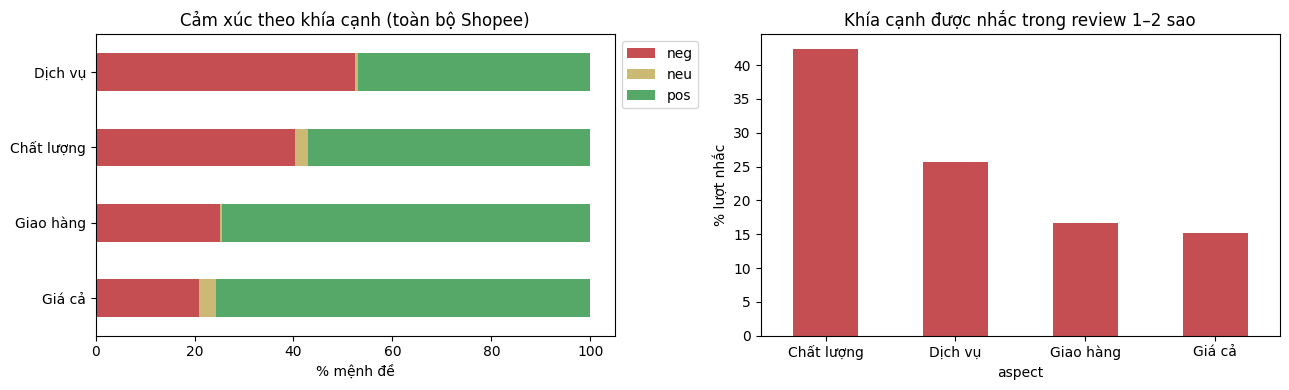

,n,neg_rate,% review nhắc tới
aspect,,,
Dịch vụ,729,0.525,0.286
Chất lượng,1501,0.403,0.589
Giao hàng,995,0.252,0.391
Giá cả,746,0.209,0.293


In [4]:
long = shp.melt(id_vars=["id", "category", "product", "rating"], value_vars=ASPECTS, var_name="aspect", value_name="sent")
long = long[long.sent != "none"]
long["aspect"] = long.aspect.map(ASP_VI)
summ = long.groupby("aspect").sent.agg(n="size", neg_rate=lambda s: (s == "neg").mean())
summ["% review nhắc tới"] = summ.n / len(shp)
summ = summ.sort_values("neg_rate", ascending=False)
summ.round(3).to_csv(f"{REP}/aspect_summary.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ct = pd.crosstab(long.aspect, long.sent, normalize="index")[["neg", "neu", "pos"]] * 100
ct.loc[summ.index[::-1]].plot.barh(stacked=True, ax=ax[0], color=["#C44E52", "#CCB974", "#55A868"])
ax[0].set(xlabel="% mệnh đề", ylabel="", title="Cảm xúc theo khía cạnh (toàn bộ Shopee)")
ax[0].legend(loc="upper left", bbox_to_anchor=(1, 1))
low = long[long.rating <= 2].aspect.value_counts(normalize=True) * 100
low.plot.bar(ax=ax[1], color="#C44E52", rot=0)
ax[1].set(ylabel="% lượt nhắc", title="Khía cạnh được nhắc trong review 1–2 sao")
plt.tight_layout(); plt.savefig(f"{FIG}/absa_overview.png", bbox_inches="tight"); plt.show()
summ.round(3)

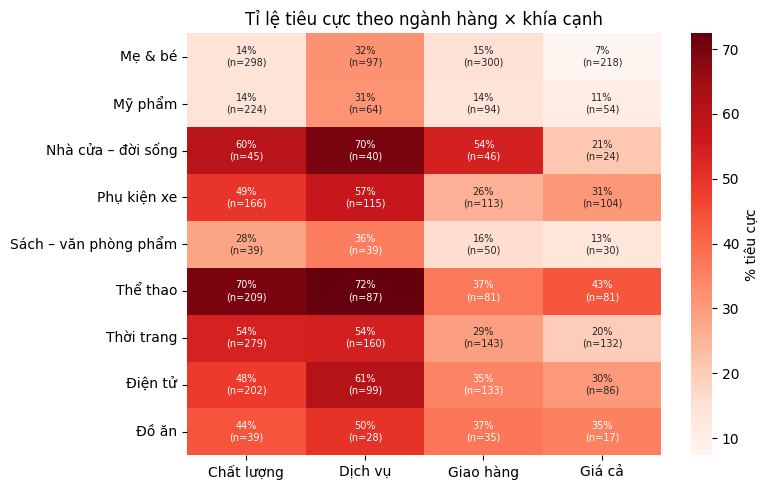

In [5]:
heat = (long.assign(is_neg=long.sent == "neg")
        .pivot_table(index="category", columns="aspect", values="is_neg", aggfunc="mean") * 100)
cnt = long.pivot_table(index="category", columns="aspect", values="id", aggfunc="size")
plt.figure(figsize=(8, 5))
sns.heatmap(heat, annot=heat.round(0).astype("Int64").astype(str) + "%\n(n=" + cnt.fillna(0).astype(int).astype(str) + ")",
            fmt="", cmap="Reds", cbar_kws={"label": "% tiêu cực"}, annot_kws={"fontsize": 7})
plt.title("Tỉ lệ tiêu cực theo ngành hàng × khía cạnh"); plt.ylabel(""); plt.xlabel("")
plt.tight_layout(); plt.savefig(f"{FIG}/absa_heatmap.png", bbox_inches="tight"); plt.show()

### "Lời chê ẩn" trong review 4–5 sao

Chủ shop lọc theo sao sẽ bỏ qua những câu này. Đây là giá trị cộng thêm của mô hình so với cách làm hiện tại.

Chỉ xét **các câu của 10 sản phẩm giữ lại** (`in_train == False`). Với 22 sản phẩm còn lại, mô hình đã học đúng nhãn sao của chúng nên gần như không bao giờ đoán 4–5 sao là neg.

In [6]:
out = shp[~shp.in_train]
hidden = out[(out.rating >= 4) & (out.pred == "neg")].sort_values("p_neg", ascending=False)
print(f"{len(hidden)} review 4–5 sao bị mô hình đánh giá là tiêu cực "
      f"({len(hidden) / (out.rating >= 4).sum():.1%} số review 4–5 sao của 10 sản phẩm giữ lại)")
hidden[["category", "rating", "p_neg", "text_clean"] + ASPECTS].head(10)

27 review 4–5 sao bị mô hình đánh giá là tiêu cực (5.0% số review 4–5 sao của 10 sản phẩm giữ lại)


,category,rating,p_neg,text_clean,giao_hang,chat_luong,gia_ca,dich_vu
1400,Thời trang,4,0.940,"nhựa hơi to xanh mint, trắng Tay ai nhỏ thì ko...",none,none,none,none
2381,Mỹ phẩm,5,0.892,thơm mà lưu hương ko lâu,none,pos,none,none
528,Mỹ phẩm,4,0.873,"nhẹ all dưỡng mụn Bôi lên mụn trứng cá, nó hết...",none,none,none,none
1231,Đồ ăn,4,0.804,n n Gu bà nàoooooo đâuu điểm danh nàoo 🧏🏻‍♀️🎁 ...,none,neg,none,none
1396,Thời trang,4,0.797,đúng nhựa xanh Nút mode bị liệt kh chỉnh h đc ...,none,none,none,neg
526,Mỹ phẩm,4,0.759,Bthg mình mua 1 đồ rất nhỏ nhiều shop gói rất ...,neg,none,none,pos
1012,Thời trang,4,0.712,đúng da silicon Tui kh nghĩ là nó dày nthe lun...,none,none,none,pos
2393,Mỹ phẩm,5,0.704,nước hoa thơm lâu,none,neg,none,none
1405,Thời trang,4,0.701,đen 🖤 nhựa tụet vòi🥹 Gất đoẹp nhà,none,none,none,none
522,Mỹ phẩm,4,0.658,k mui mụn giảm mụn Giảm mụn tuýp nhỏ. Sài dc t...,none,none,none,none


## 4. Ba vấn đề cần cải thiện

Ưu tiên theo lượt dự đoán chê rồi đọc xác minh. Mẫu số là lượt nhắc khía cạnh, không phải đơn hàng/tỷ lệ hàng lỗi. Thống kê chứa train, chỉ mô tả theo dự đoán.

In [7]:
cand = (long.groupby(["category", "aspect"]).sent
        .agg(n_nhac="size", n_che=lambda s: (s == "neg").sum(), ti_le_che=lambda s: (s == "neg").mean())
        .query("n_nhac >= 15").sort_values("n_che", ascending=False).head(8))
cand.round(3).to_csv(f"{REP}/top_issue_candidates.csv", encoding="utf-8-sig")
cand.round(3)

n_nhac  n_che  ti_le_che
category    aspect                              
Thời trang  Chất lượng     279    150      0.538
Thể thao    Chất lượng     209    146      0.699
Điện tử     Chất lượng     202     97      0.480
Thời trang  Dịch vụ        160     87      0.544
Phụ kiện xe Chất lượng     166     82      0.494
            Dịch vụ        115     66      0.574
Thể thao    Dịch vụ         87     63      0.724
Điện tử     Dịch vụ         99     60      0.606

In [8]:
key = {v: k for k, v in ASP_VI.items()}
for (cat, a), r in cand.head(3).iterrows():
    print(f"=== {cat} – {a}: {r.n_che} lượt chê / {r.n_nhac} lượt nhắc ({r.ti_le_che:.0%}) ===")
    q = shp[(shp.category == cat) & (shp[key[a]] == "neg")].sort_values("p_neg", ascending=False)
    for s in q.text_clean.head(3):
        print("  •", s[:200])
    print()

=== Thời trang – Chất lượng: 150.0 lượt chê / 279.0 lượt nhắc (54%) ===
  • Đó giờ rất ít khi đánh giá ai 1* nhưng lần này Gumac làm t quá thất vọng r. Cần hàng gấp tặng quà sn mới đặt hỏa tốc, đặt lúc 14h t7 mà shop ko book grab kịp rồi để qua t2 mới giao luôn, vậy là hỏa tố
  • Chất lượng thì kém nịt vào kh hiểu sao nó bị kẹt cứng không tháo ra được phải cắt đi làm ăn vậy dẹp mẹ shop đi
  • đen Thật sự là rất thất vọng về sản phẩm, đường may của balo bị lệch rất nhiều, nhắn tin để shop giải quyết thì k thấy nhắn lại thật sự rất thất vọng

=== Thể thao – Chất lượng: 146.0 lượt chê / 209.0 lượt nhắc (70%) ===
  • quá tệ đá tý đã bung chỉ
  • Chất lượng quá tệ! Mới bơm lên đã bung chỉ may, sắp nổ! Không đáng tiền
  • không đúng mô tả den Vải quá mỏng ko giống với ảnh. Quần rất mong rát, mới mang ngồi xuống rách lun. Quá thất vọng shop.

=== Điện tử – Chất lượng: 97.0 lượt chê / 202.0 lượt nhắc (48%) ===
  • giao sai màu k hỏi khách hàng tự ý đổi và giao luôn kì vải ,sạc thì k lên pin th

Ba ưu tiên chọn theo số lượt dự đoán chê trong `top_issue_candidates.csv`, sau đó đọc lại ví dụ. Mẫu số là review được nhận diện nhắc khía cạnh, không phải toàn review ngành. Trích đoạn từ `shopee_predicted.csv` giữ cách viết của khách; mã review để đối chiếu, không phải định danh. KPI là đề xuất, chưa phải kết quả đạt được.

### Chất lượng hàng thời trang

Có 150/279 lượt nhắc Chất lượng dự đoán tiêu cực (53,8%). Ví dụ: “đường may của balo bị lệch rất nhiều” (`shp_0985`); “Đã nhận, đường may bị méo, thất vọng” (`shp_0992`); “Chất lượng thì kém nịt vào kh hiểu sao nó bị kẹt cứng không tháo ra được” (`shp_0232`, trích đoạn).

Đề xuất phiếu kiểm theo loại hàng: đường may, khóa, màu/mẫu; ghi mã lô để truy nguyên. CSKH xin bằng chứng và chuyển kho xác minh trước đổi trả. **KPI đề xuất:** tỷ lệ phản ánh chất lượng xác nhận trên review nhắc chất lượng, thời gian phản hồi và tỷ lệ đổi trả do lỗi. Tháng thử nghiệm đầu thiết lập mốc nền bằng kiểm tra tay, sau đó chốt mức giảm mục tiêu. Không lấy 53,8% dự đoán làm tỷ lệ hàng lỗi thật.

### Độ bền và vật liệu sản phẩm thể thao

Có 146/209 lượt nhắc Chất lượng dự đoán tiêu cực (69,9%). Ví dụ: “quá tệ đá tý đã bung chỉ” (`shp_1719`); “Chất lượng quá tệ! Mới bơm lên đã bung chỉ may, sắp nổ! Không đáng tiền” (`shp_1727`); “Vải quá mỏng ko giống với ảnh” (`shp_1601`, trích đoạn).

Đề xuất kiểm tra độ bền đường may/vật liệu theo lô, bổ sung hình thật và mô tả độ dày/cách dùng. **KPI đề xuất:** tỷ lệ khiếu nại bung chỉ/rách xác nhận trên review nhắc chất lượng, tỷ lệ lô đạt kiểm tra, tỷ lệ đổi trả do độ bền. So sánh trước–sau cùng danh mục và cách gán nhãn; chưa kết luận hiệu quả khi cơ cấu hàng thay đổi.

### Chức năng sử dụng hàng điện tử

Có 97/202 lượt nhắc Chất lượng dự đoán tiêu cực (48,0%). Ví dụ: “sạc ko vào pin Sạc thử điện thoại 30p ko lên % nào” (`shp_1779`); “Hàng nhận được hư 2 cổng usb” (`shp_1791`); “Sản phẩm mới dùng sạc được 1 lần đã bị hỏng quá thất vọng” (`shp_0615`). Đây là phản ánh khách, chưa phải giám định kỹ thuật.

Đề xuất kiểm tra chức năng trước đóng gói, ghi lô phụ kiện và hướng dẫn tương thích; phản ánh hỏng/mất an toàn cần nhân viên ưu tiên. **KPI đề xuất:** tỷ lệ lỗi chức năng xác nhận, thời gian phản hồi đầu tiên và tỷ lệ hoàn tất đổi/bảo hành. Tách lỗi kỹ thuật khỏi giao nhầm/thiếu để tránh sai trách nhiệm.

Top từ khóa giúp tìm review nhưng không thay việc kiểm tra. Từ “không”, “như”, “quá” xuất hiện nhiều mà không nêu nguyên nhân cụ thể. Ưu tiên hành động cần kết hợp lượt chê, tỷ lệ chê, mức nghiêm trọng và xác minh của nhân viên.

## 5. Word cloud theo khía cạnh × tiêu cực

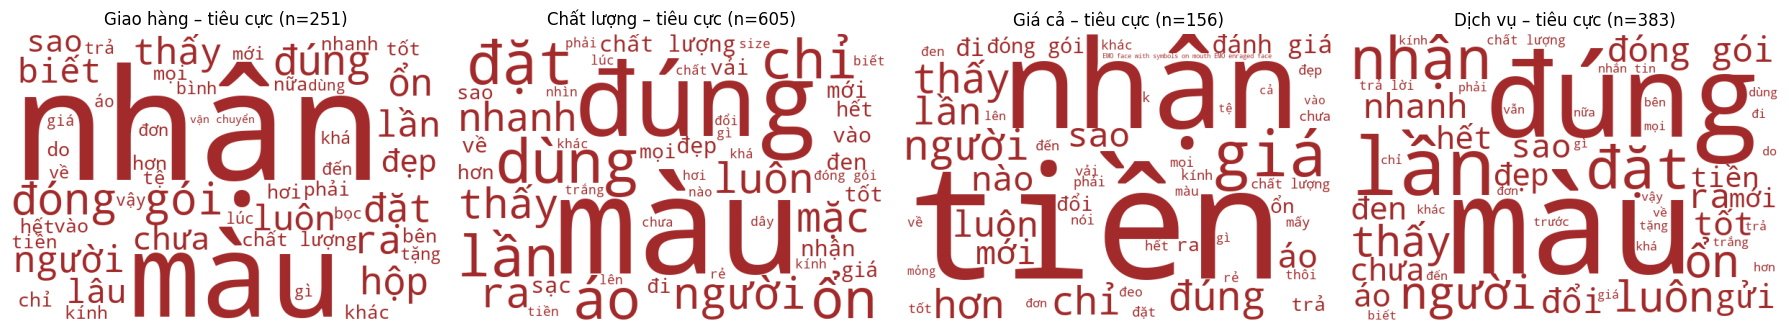

In [9]:
from wordcloud import WordCloud
from src.aspects import word_freq
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, a in zip(axes, ASPECTS):
    freq = word_freq(shp[shp[a] == "neg"].text_prep)
    if freq:
        wc = WordCloud(width=600, height=400, background_color="white", max_words=50, prefer_horizontal=1.0,
                       color_func=lambda *args, **kw: "#A32A2A", random_state=42).generate_from_frequencies(freq)
        ax.imshow(wc)
    ax.axis("off"); ax.set_title(f"{ASP_VI[a]} – tiêu cực (n={(shp[a] == 'neg').sum()})")
plt.tight_layout(); plt.savefig(f"{FIG}/wordcloud_aspect_neg.png", bbox_inches="tight", dpi=150); plt.show()


## 6. Top từ khóa tiêu cực

Đề yêu cầu dashboard có top negative keywords. Một từ được giữ nếu có trong ít nhất 5 review chê và ít nhất 50% review chứa nó bị chê, để loại các từ chung như "hàng", "sản phẩm".

In [10]:
from src.aspects import top_negative_keywords
kw = top_negative_keywords(shp)
kw.to_csv(f"{REP}/top_negative_keywords.csv", index=False, encoding="utf-8-sig")
kw

,Từ khóa,Số review chê,Tỉ lệ chê
1,không,501,0.555
4,như,163,0.560
11,quá,134,0.565
19,chỉ,110,0.625
3,đặt,105,0.583
14,ra,104,0.654
73,hết,82,0.726
7,tiền,80,0.513
33,về,77,0.535
55,đi,77,0.631
